In [2]:
from pathlib import Path

print(Path.cwd())


/Users/sneha/credit-card-fraud-xai/notebooks


In [3]:
PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "creditcard.csv"

print(DATA_PATH)
print(DATA_PATH.exists())

/Users/sneha/credit-card-fraud-xai/data/raw/creditcard.csv
True


In [7]:
df = pd.read_csv(DATA_PATH)

In [5]:
import pandas as pd

In [8]:
df.shape

(284807, 31)

In [9]:
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='str')

In [10]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [11]:
df["Class"].value_counts()

Class
0    284315
1       492
Name: count, dtype: int64

In [12]:
df["Class"].value_counts(normalize=True) * 100

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64

In [13]:
df.dtypes

Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

In [14]:
df.isnull().sum()

Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

In [15]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [16]:
df.groupby("Class")["Amount"].agg(["count", "mean", "median", "min", "max"])

,count,mean,median,min,max
Class,,,,,
0,284315,88.291022,22.00,0.0,25691.16
1,492,122.211321,9.25,0.0,2125.87


In [17]:
df["Amount_Bin"] = pd.qcut(
    df["Amount"],
    q=10,
    duplicates="drop"
)

df.groupby("Amount_Bin", observed=True)["Class"].agg(
    transactions="count",
    frauds="sum",
    fraud_rate="mean"
)

,transactions,frauds,fraud_rate
Amount_Bin,,,
"(-0.001, 1.0]",30492,181,0.005936
"(1.0, 3.57]",26473,27,0.001020
"(3.57, 8.91]",28559,36,0.001261
"(8.91, 13.0]",28405,13,0.000458
"(13.0, 22.0]",28714,14,0.000488
"(22.0, 37.0]",28375,17,0.000599
"(37.0, 59.8]",28366,24,0.000846
"(59.8, 100.0]",28915,50,0.001729
"(100.0, 203.0]",28050,45,0.001604


In [19]:
df.drop(columns="Amount_Bin", inplace=True)

KeyError: "['Amount_Bin'] not found in axis"

In [20]:
"Amount_Bin" in df.columns

False

In [21]:
class_means = df.groupby("Class").mean(numeric_only=True).T

class_means["difference"] = (
    class_means[1] - class_means[0]
)

class_means.sort_values(
    "difference",
    key=abs,
    ascending=False
).head(10)

Class,0,1,difference
Time,94838.202258,80746.806911,-14091.395347
Amount,88.291022,122.211321,33.920299
V3,0.012171,-7.033281,-7.045452
V14,0.012064,-6.971723,-6.983787
V17,0.011535,-6.665836,-6.677371
V12,0.010832,-6.259393,-6.270225
V10,0.009824,-5.676883,-5.686707
V7,0.009637,-5.568731,-5.578368
V1,0.008258,-4.771948,-4.780206
V4,-0.007860,4.542029,4.549889


In [22]:
df.groupby("Class")["V14"].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,0.012064,0.897007,-18.392091,-0.422453,0.051947,0.494104,10.526766
1,492.0,-6.971723,4.278940,-19.214325,-9.692723,-6.729720,-4.282821,3.442422


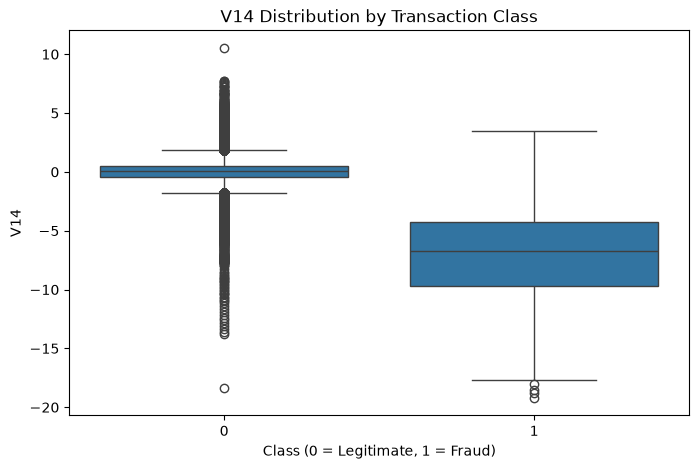

In [23]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Class",
    y="V14"
)

plt.title("V14 Distribution by Transaction Class")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("V14")
plt.show()

In [24]:
correlation_with_class = (
    df.corr(numeric_only=True)["Class"]
    .drop("Class")
    .sort_values(key=abs, ascending=False)
)

correlation_with_class.head(10)

V17   -0.326481
V14   -0.302544
V12   -0.260593
V10   -0.216883
V16   -0.196539
V3    -0.192961
V7    -0.187257
V11    0.154876
V4     0.133447
V18   -0.111485
Name: Class, dtype: float64

In [25]:
df.groupby("Class")["Time"].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,94838.202258,47484.015786,0.0,54230.0,84711.0,139333.0,172792.0
1,492.0,80746.806911,47835.365138,406.0,41241.5,75568.5,128483.0,170348.0


In [26]:
df["Time_Bin"] = pd.qcut(
    df["Time"],
    q=10,
    duplicates="drop"
)

df.groupby("Time_Bin", observed=True)["Class"].agg(
    transactions="count",
    frauds="sum",
    fraud_rate="mean"
)

,transactions,frauds,fraud_rate
Time_Bin,,,
"(-0.001, 35027.0]",28482,93,0.003265
"(35027.0, 47694.2]",28480,64,0.002247
"(47694.2, 60776.0]",28483,47,0.001650
"(60776.0, 73261.4]",28478,37,0.001299
"(73261.4, 84692.0]",28481,28,0.000983
"(84692.0, 120396.0]",28484,91,0.003195
"(120396.0, 132929.0]",28480,24,0.000843
"(132929.0, 145247.8]",28477,33,0.001159
"(145247.8, 157640.4]",28481,53,0.001861


In [27]:
df.drop(columns=["Time_Bin"], inplace=True)

print("Time_Bin" in df.columns)

False


In [28]:
df.duplicated().sum()

np.int64(1081)

In [29]:
df[df.duplicated(keep=False)].sort_values(
    by=["Time", "Amount"]
).head(10)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
34,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
32,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
112,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
113,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
114,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
115,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
220,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0
221,145.0,-2.420413,1.947885,0.553646,0.983069,-0.281518,2.408958,-1.401613,-0.188299,0.675878,...,1.213826,-1.238620,0.006927,-1.724222,0.239603,-0.313703,-0.188281,0.119831,6.00,0


In [30]:
df[df.duplicated(keep=False)]["Class"].value_counts()

Class
0    1822
1      32
Name: count, dtype: int64

In [31]:
df.drop_duplicates().shape

(283726, 31)

In [32]:
df.drop_duplicates()["Class"].value_counts()

Class
0    283253
1       473
Name: count, dtype: int64

In [33]:
df = df.drop_duplicates().copy()

print(df.shape)
print(df["Class"].value_counts())

(283726, 31)
Class
0    283253
1       473
Name: count, dtype: int64


In [34]:
df.nunique().sort_values()

Class          2
Amount     32767
Time      124592
V3        275663
V28       275663
V27       275663
V26       275663
V25       275663
V24       275663
V23       275663
V22       275663
V21       275663
V20       275663
V19       275663
V18       275663
V17       275663
V16       275663
V1        275663
V14       275663
V13       275663
V12       275663
V11       275663
V10       275663
V9        275663
V8        275663
V7        275663
V6        275663
V5        275663
V4        275663
V2        275663
V15       275663
dtype: int64

In [35]:
X = df.drop(columns=["Class"])
y = df["Class"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())

X shape: (283726, 30)
y shape: (283726,)

Target distribution:
Class
0    283253
1       473
Name: count, dtype: int64


In [36]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("\ny_train:")
print(y_train.value_counts())

print("\ny_test:")
print(y_test.value_counts())

X_train: (226980, 30)
X_test: (56746, 30)

y_train:
Class
0    226602
1       378
Name: count, dtype: int64

y_test:
Class
0    56651
1       95
Name: count, dtype: int64


In [37]:
X_train.describe().loc[["mean", "std"]].T

,mean,std
Time,94900.224390,47488.214282
V1,0.005027,1.947293
V2,-0.005549,1.649617
V3,0.002131,1.507270
V4,-0.002025,1.416960
V5,0.004941,1.359643
V6,-0.001961,1.323401
V7,0.001480,1.200181
V8,-0.000215,1.169342
V9,-0.002883,1.094055


In [38]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled shape:", X_train_scaled.shape)
print("X_test_scaled shape:", X_test_scaled.shape)

X_train_scaled shape: (226980, 30)
X_test_scaled shape: (56746, 30)


In [39]:
from sklearn.linear_model import LogisticRegression

baseline_lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

baseline_lr.fit(X_train_scaled, y_train)

print("Baseline Logistic Regression trained successfully.")

Baseline Logistic Regression trained successfully.


In [40]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    average_precision_score
)

y_pred_baseline = baseline_lr.predict(X_test_scaled)
y_proba_baseline = baseline_lr.predict_proba(X_test_scaled)[:, 1]

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_baseline))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_baseline, digits=4))

print("PR-AUC:", average_precision_score(y_test, y_proba_baseline))

Confusion Matrix:
[[56641    10]
 [   40    55]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9993    0.9998    0.9996     56651
           1     0.8462    0.5789    0.6875        95

    accuracy                         0.9991     56746
   macro avg     0.9227    0.7894    0.8435     56746
weighted avg     0.9990    0.9991    0.9990     56746

PR-AUC: 0.6919665484964556


In [41]:
pd.DataFrame({
    "Actual_Class": y_test.values,
    "Fraud_Probability": y_proba_baseline
}).groupby("Actual_Class")["Fraud_Probability"].describe()

,count,mean,std,min,25%,50%,75%,max
Actual_Class,,,,,,,,
0,56651.0,0.000552,0.013020,2.065348e-09,0.000106,0.000185,0.000336,0.999997
1,95.0,0.584526,0.425811,7.583487e-05,0.087361,0.772484,0.994580,1.000000


In [42]:
weighted_lr = LogisticRegression(
    class_weight="balanced",
    max_iter=1000,
    random_state=42
)

weighted_lr.fit(X_train_scaled, y_train)

print("Class-weighted Logistic Regression trained successfully.")

Class-weighted Logistic Regression trained successfully.


In [43]:
y_pred_weighted = weighted_lr.predict(X_test_scaled)
y_proba_weighted = weighted_lr.predict_proba(X_test_scaled)[:, 1]

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_weighted))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_weighted, digits=4))

print("PR-AUC:", average_precision_score(y_test, y_proba_weighted))

Confusion Matrix:
[[55262  1389]
 [   12    83]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9998    0.9755    0.9875     56651
           1     0.0564    0.8737    0.1059        95

    accuracy                         0.9753     56746
   macro avg     0.5281    0.9246    0.5467     56746
weighted avg     0.9982    0.9753    0.9860     56746

PR-AUC: 0.6719244530518994


In [44]:
print("Before SMOTE:")
print(y_train.value_counts())

Before SMOTE:
Class
0    226602
1       378
Name: count, dtype: int64


In [45]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(
    random_state=42
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("After SMOTE:")
print(y_train_smote.value_counts())
print("\nNew training shape:", X_train_smote.shape)

After SMOTE:
Class
0    226602
1    226602
Name: count, dtype: int64

New training shape: (453204, 30)


In [46]:
smote_lr = LogisticRegression(
    max_iter=1000,
    random_state=42
)

smote_lr.fit(X_train_smote, y_train_smote)

print("SMOTE Logistic Regression trained successfully.")

SMOTE Logistic Regression trained successfully.


In [47]:
y_pred_smote = smote_lr.predict(X_test_scaled)
y_proba_smote = smote_lr.predict_proba(X_test_scaled)[:, 1]

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_smote))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_smote, digits=4))

print("PR-AUC:", average_precision_score(y_test, y_proba_smote))

Confusion Matrix:
[[55169  1482]
 [   12    83]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9998    0.9738    0.9866     56651
           1     0.0530    0.8737    0.1000        95

    accuracy                         0.9737     56746
   macro avg     0.5264    0.9238    0.5433     56746
weighted avg     0.9982    0.9737    0.9852     56746

PR-AUC: 0.6750409387333339


In [48]:
from xgboost import XGBClassifier

xgb_baseline = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1
)

xgb_baseline.fit(X_train, y_train)

print("XGBoost baseline trained successfully.")

XGBoost baseline trained successfully.


In [49]:
y_pred_xgb = xgb_baseline.predict(X_test)
y_proba_xgb = xgb_baseline.predict_proba(X_test)[:, 1]

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_xgb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb, digits=4))

print("PR-AUC:", average_precision_score(y_test, y_proba_xgb))

Confusion Matrix:
[[56649     2]
 [   24    71]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9996    1.0000    0.9998     56651
           1     0.9726    0.7474    0.8452        95

    accuracy                         0.9995     56746
   macro avg     0.9861    0.8737    0.9225     56746
weighted avg     0.9995    0.9995    0.9995     56746

PR-AUC: 0.8402548103550002


In [50]:
pd.DataFrame({
    "Actual_Class": y_test.values,
    "Fraud_Probability": y_proba_xgb
}).groupby("Actual_Class")["Fraud_Probability"].describe()

,count,mean,std,min,25%,50%,75%,max
Actual_Class,,,,,,,,
0,56651.0,0.000138,0.006324,1.795541e-07,0.000003,0.000008,0.000023,0.986919
1,95.0,0.735445,0.408375,7.215489e-06,0.591743,0.981561,0.993326,0.999284


In [51]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(
    y_test,
    y_proba_xgb
)

print("Number of thresholds:", len(thresholds))
print("Precision values:", len(precision))
print("Recall values:", len(recall))

Number of thresholds: 56010
Precision values: 56011
Recall values: 56011


In [52]:
from sklearn.metrics import precision_score, recall_score

for threshold in [0.10, 0.20, 0.30, 0.40, 0.50]:
    y_pred_threshold = (y_proba_xgb >= threshold).astype(int)

    precision_value = precision_score(y_test, y_pred_threshold)
    recall_value = recall_score(y_test, y_pred_threshold)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision_value:.4f} | "
        f"Recall: {recall_value:.4f}"
    )

Threshold: 0.10 | Precision: 0.8916 | Recall: 0.7789
Threshold: 0.20 | Precision: 0.9241 | Recall: 0.7684
Threshold: 0.30 | Precision: 0.9474 | Recall: 0.7579
Threshold: 0.40 | Precision: 0.9474 | Recall: 0.7579
Threshold: 0.50 | Precision: 0.9726 | Recall: 0.7474


In [53]:
from sklearn.model_selection import train_test_split

X_train_model, X_val, y_train_model, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    stratify=y_train,
    random_state=42
)

print("Training:", X_train_model.shape)
print("Validation:", X_val.shape)

print("\nTraining class distribution:")
print(y_train_model.value_counts())

print("\nValidation class distribution:")
print(y_val.value_counts())

Training: (181584, 30)
Validation: (45396, 30)

Training class distribution:
Class
0    181282
1       302
Name: count, dtype: int64

Validation class distribution:
Class
0    45320
1       76
Name: count, dtype: int64


In [54]:
xgb_val = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1
)

xgb_val.fit(X_train_model, y_train_model)

print("Validation XGBoost trained.")

Validation XGBoost trained.


In [55]:
y_proba_val = xgb_val.predict_proba(X_val)[:, 1]

print("Validation probabilities:", y_proba_val.shape)
print("Min:", y_proba_val.min())
print("Max:", y_proba_val.max())

Validation probabilities: (45396,)
Min: 1.4251306e-07
Max: 0.9994294


In [56]:
from sklearn.metrics import precision_recall_curve

precision_val, recall_val, thresholds_val = precision_recall_curve(
    y_val,
    y_proba_val
)

print("Number of thresholds:", len(thresholds_val))
print("Precision values:", len(precision_val))
print("Recall values:", len(recall_val))

Number of thresholds: 44845
Precision values: 44846
Recall values: 44846


In [57]:
from sklearn.metrics import precision_score, recall_score

for threshold in [0.10, 0.20, 0.30, 0.40, 0.50]:
    y_pred_val = (y_proba_val >= threshold).astype(int)

    precision_value = precision_score(y_val, y_pred_val)
    recall_value = recall_score(y_val, y_pred_val)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision_value:.4f} | "
        f"Recall: {recall_value:.4f}"
    )

Threshold: 0.10 | Precision: 0.9429 | Recall: 0.8684
Threshold: 0.20 | Precision: 0.9697 | Recall: 0.8421
Threshold: 0.30 | Precision: 0.9846 | Recall: 0.8421
Threshold: 0.40 | Precision: 0.9844 | Recall: 0.8289
Threshold: 0.50 | Precision: 0.9841 | Recall: 0.8158


In [58]:
from sklearn.metrics import f1_score

for threshold in [0.10, 0.20, 0.30, 0.40, 0.50]:
    y_pred_val = (y_proba_val >= threshold).astype(int)

    precision_value = precision_score(y_val, y_pred_val)
    recall_value = recall_score(y_val, y_pred_val)
    f1_value = f1_score(y_val, y_pred_val)

    print(
        f"Threshold: {threshold:.2f} | "
        f"Precision: {precision_value:.4f} | "
        f"Recall: {recall_value:.4f} | "
        f"F1: {f1_value:.4f}"
    )

Threshold: 0.10 | Precision: 0.9429 | Recall: 0.8684 | F1: 0.9041
Threshold: 0.20 | Precision: 0.9697 | Recall: 0.8421 | F1: 0.9014
Threshold: 0.30 | Precision: 0.9846 | Recall: 0.8421 | F1: 0.9078
Threshold: 0.40 | Precision: 0.9844 | Recall: 0.8289 | F1: 0.9000
Threshold: 0.50 | Precision: 0.9841 | Recall: 0.8158 | F1: 0.8921


In [59]:
import numpy as np

f1_scores = (
    2 * precision_val * recall_val
    / (precision_val + recall_val + 1e-10)
)

best_idx = np.argmax(f1_scores)

best_threshold = thresholds_val[best_idx]
best_f1 = f1_scores[best_idx]

print("Best validation threshold:", best_threshold)
print("Best validation F1:", best_f1)
print("Precision at best threshold:", precision_val[best_idx])
print("Recall at best threshold:", recall_val[best_idx])

Best validation threshold: 0.38788387
Best validation F1: 0.9078014183900206
Precision at best threshold: 0.9846153846153847
Recall at best threshold: 0.8421052631578947


In [60]:
final_threshold = best_threshold

y_pred_test_threshold = (
    y_proba_xgb >= final_threshold
).astype(int)

print("Threshold:", final_threshold)
print("Predicted fraud:", y_pred_test_threshold.sum())
print("Actual fraud:", y_test.sum())

Threshold: 0.38788387
Predicted fraud: 76
Actual fraud: 95


In [61]:
from sklearn.metrics import confusion_matrix

cm_threshold = confusion_matrix(
    y_test,
    y_pred_test_threshold
)

print(cm_threshold)

[[56647     4]
 [   23    72]]


In [62]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

precision_final = precision_score(y_test, y_pred_test_threshold)
recall_final = recall_score(y_test, y_pred_test_threshold)
f1_final = f1_score(y_test, y_pred_test_threshold)

print("Precision:", precision_final)
print("Recall:", recall_final)
print("F1:", f1_final)
print("PR-AUC:", average_precision_score(y_test, y_proba_xgb))

Precision: 0.9473684210526315
Recall: 0.7578947368421053
F1: 0.8421052631578947
PR-AUC: 0.8402548103550002


In [63]:
# Scenario-based business cost assumptions
C_FP = 1      # Cost of unnecessarily flagging a legitimate transaction
C_FN = 10     # Cost of missing a fraudulent transaction

print("False Positive Cost:", C_FP)
print("False Negative Cost:", C_FN)

False Positive Cost: 1
False Negative Cost: 10


In [64]:
FP = cm_threshold[0, 1]
FN = cm_threshold[1, 0]

total_cost = (FP * C_FP) + (FN * C_FN)

print("False Positives:", FP)
print("False Negatives:", FN)
print("Total Scenario Cost:", total_cost)

False Positives: 4
False Negatives: 23
Total Scenario Cost: 234


In [65]:
cost_05 = (2 * C_FP) + (24 * C_FN)

print("Threshold 0.50 Cost:", cost_05)
print("Threshold 0.3879 Cost:", total_cost)

Threshold 0.50 Cost: 242
Threshold 0.3879 Cost: 234


In [66]:
for fn_cost in [5, 10, 20, 50]:
    cost_threshold = (4 * C_FP) + (23 * fn_cost)
    
    print(
        f"FN Cost = {fn_cost:>2} | "
        f"Threshold 0.3879 Scenario Cost = {cost_threshold}"
    )

FN Cost =  5 | Threshold 0.3879 Scenario Cost = 119
FN Cost = 10 | Threshold 0.3879 Scenario Cost = 234
FN Cost = 20 | Threshold 0.3879 Scenario Cost = 464
FN Cost = 50 | Threshold 0.3879 Scenario Cost = 1154


In [67]:
for threshold in [0.10, 0.20, 0.30, 0.40, 0.50]:
    y_pred = (y_proba_xgb >= threshold).astype(int)
    cm = confusion_matrix(y_test, y_pred)

    FP = cm[0, 1]
    FN = cm[1, 0]

    cost = (FP * C_FP) + (FN * C_FN)

    print(
        f"Threshold: {threshold:.2f} | "
        f"FP: {FP:>3} | "
        f"FN: {FN:>2} | "
        f"Cost: {cost}"
    )

Threshold: 0.10 | FP:   9 | FN: 21 | Cost: 219
Threshold: 0.20 | FP:   6 | FN: 22 | Cost: 226
Threshold: 0.30 | FP:   4 | FN: 23 | Cost: 234
Threshold: 0.40 | FP:   4 | FN: 23 | Cost: 234
Threshold: 0.50 | FP:   2 | FN: 24 | Cost: 242


In [68]:
threshold = 0.10

y_pred_val_cost = (y_proba_val >= threshold).astype(int)
cm_val_cost = confusion_matrix(y_val, y_pred_val_cost)

FP_val = cm_val_cost[0, 1]
FN_val = cm_val_cost[1, 0]

cost_val = (FP_val * C_FP) + (FN_val * C_FN)

print("Threshold:", threshold)
print("FP:", FP_val)
print("FN:", FN_val)
print("Scenario Cost:", cost_val)

Threshold: 0.1
FP: 4
FN: 10
Scenario Cost: 104


In [69]:
for threshold in [0.10, 0.20, 0.30, 0.40, 0.50]:
    y_pred_val_cost = (y_proba_val >= threshold).astype(int)
    cm_val_cost = confusion_matrix(y_val, y_pred_val_cost)

    FP_val = cm_val_cost[0, 1]
    FN_val = cm_val_cost[1, 0]

    cost_val = (FP_val * C_FP) + (FN_val * C_FN)

    print(
        f"Threshold: {threshold:.2f} | "
        f"FP: {FP_val:>3} | "
        f"FN: {FN_val:>2} | "
        f"Scenario Cost: {cost_val}"
    )

Threshold: 0.10 | FP:   4 | FN: 10 | Scenario Cost: 104
Threshold: 0.20 | FP:   2 | FN: 12 | Scenario Cost: 122
Threshold: 0.30 | FP:   1 | FN: 12 | Scenario Cost: 121
Threshold: 0.40 | FP:   1 | FN: 13 | Scenario Cost: 131
Threshold: 0.50 | FP:   1 | FN: 14 | Scenario Cost: 141


In [70]:
for fn_cost in [5, 10, 20, 50]:

    print(f"\nFN Cost = {fn_cost}")

    for threshold in [0.10, 0.20, 0.30, 0.40, 0.50]:

        y_pred_val_cost = (y_proba_val >= threshold).astype(int)
        cm = confusion_matrix(y_val, y_pred_val_cost)

        FP_val = cm[0, 1]
        FN_val = cm[1, 0]

        cost = (FP_val * C_FP) + (FN_val * fn_cost)

        print(
            f"Threshold {threshold:.2f} | "
            f"FP={FP_val} | FN={FN_val} | Cost={cost}"
        )


FN Cost = 5
Threshold 0.10 | FP=4 | FN=10 | Cost=54
Threshold 0.20 | FP=2 | FN=12 | Cost=62
Threshold 0.30 | FP=1 | FN=12 | Cost=61
Threshold 0.40 | FP=1 | FN=13 | Cost=66
Threshold 0.50 | FP=1 | FN=14 | Cost=71

FN Cost = 10
Threshold 0.10 | FP=4 | FN=10 | Cost=104
Threshold 0.20 | FP=2 | FN=12 | Cost=122
Threshold 0.30 | FP=1 | FN=12 | Cost=121
Threshold 0.40 | FP=1 | FN=13 | Cost=131
Threshold 0.50 | FP=1 | FN=14 | Cost=141

FN Cost = 20
Threshold 0.10 | FP=4 | FN=10 | Cost=204
Threshold 0.20 | FP=2 | FN=12 | Cost=242
Threshold 0.30 | FP=1 | FN=12 | Cost=241
Threshold 0.40 | FP=1 | FN=13 | Cost=261
Threshold 0.50 | FP=1 | FN=14 | Cost=281

FN Cost = 50
Threshold 0.10 | FP=4 | FN=10 | Cost=504
Threshold 0.20 | FP=2 | FN=12 | Cost=602
Threshold 0.30 | FP=1 | FN=12 | Cost=601
Threshold 0.40 | FP=1 | FN=13 | Cost=651
Threshold 0.50 | FP=1 | FN=14 | Cost=701


In [72]:
# Efficient cost calculation across all validation thresholds

P = y_val.sum()

TP = recall_val[:-1] * P
predicted_positive = TP / precision_val[:-1]
FP = predicted_positive - TP
FN = P - TP

costs = (FP * C_FP) + (FN * C_FN)

best_cost_idx = np.argmin(costs)

best_cost_threshold = thresholds_val[best_cost_idx]
best_cost = costs[best_cost_idx]

print("Best cost threshold:", best_cost_threshold)
print("Minimum validation cost:", best_cost)

Best cost threshold: 0.10888907
Minimum validation cost: 104


In [73]:
X_train_final = pd.concat([X_train_model, X_val])
y_train_final = pd.concat([y_train_model, y_val])

print("Final training shape:", X_train_final.shape)
print("Final target distribution:")
print(y_train_final.value_counts())

Final training shape: (226980, 30)
Final target distribution:
Class
0    226602
1       378
Name: count, dtype: int64


In [74]:
xgb_final = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="aucpr",
    random_state=42,
    n_jobs=-1
)

xgb_final.fit(X_train_final, y_train_final)

print("Final XGBoost trained.")

Final XGBoost trained.


In [75]:
y_proba_final = xgb_final.predict_proba(X_test)[:, 1]

print("Test probabilities:", y_proba_final.shape)
print("Min:", y_proba_final.min())
print("Max:", y_proba_final.max())

Test probabilities: (56746,)
Min: 1.1882818e-07
Max: 0.9993315


In [76]:
final_cost_threshold = best_cost_threshold

y_pred_final_cost = (
    y_proba_final >= final_cost_threshold
).astype(int)

print("Final threshold:", final_cost_threshold)
print("Predicted fraud:", y_pred_final_cost.sum())
print("Actual fraud:", y_test.sum())

Final threshold: 0.10888907
Predicted fraud: 80
Actual fraud: 95


In [77]:
cm_final_cost = confusion_matrix(
    y_test,
    y_pred_final_cost
)

print(cm_final_cost)

[[56645     6]
 [   21    74]]


In [78]:
precision_final_cost = precision_score(y_test, y_pred_final_cost)
recall_final_cost = recall_score(y_test, y_pred_final_cost)
f1_final_cost = f1_score(y_test, y_pred_final_cost)
pr_auc_final = average_precision_score(y_test, y_proba_final)

print("Precision:", precision_final_cost)
print("Recall:", recall_final_cost)
print("F1:", f1_final_cost)
print("PR-AUC:", pr_auc_final)

Precision: 0.925
Recall: 0.7789473684210526
F1: 0.8457142857142858
PR-AUC: 0.830839754748145


In [80]:
import shap

explainer = shap.TreeExplainer(xgb_final)

shap_values = explainer.shap_values(X_test)

shap_values.shape

(56746, 30)

In [81]:
shap_importance = pd.DataFrame({
    "Feature": X_test.columns,
    "Mean_Abs_SHAP": np.abs(shap_values).mean(axis=0)
}).sort_values("Mean_Abs_SHAP", ascending=False)

shap_importance.head(10)

,Feature,Mean_Abs_SHAP
4,V4,1.114189
12,V12,0.849733
10,V10,0.823256
14,V14,0.796635
11,V11,0.301775
19,V19,0.253577
8,V8,0.232128
3,V3,0.226617
29,Amount,0.223871
21,V21,0.217977


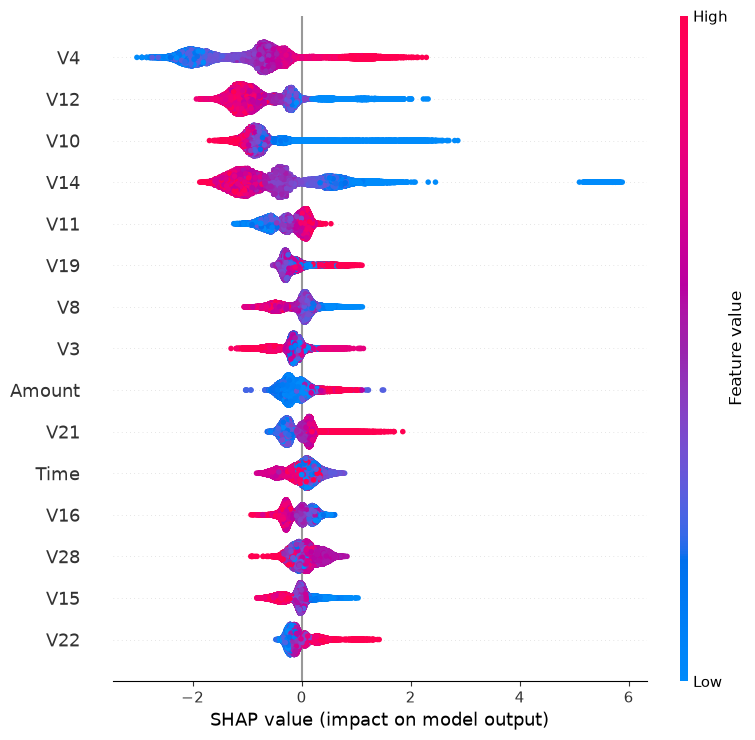

In [82]:
shap.summary_plot(
    shap_values,
    X_test,
    max_display=15
)

In [83]:
fraud_detected_idx = X_test.index[
    (y_test == 1) & (y_pred_final_cost == 1)
]

fraud_detected_idx[:10]

Index([116139, 95597, 240222, 203700, 143188, 42009, 6609, 15476, 151807,
       154234],
      dtype='int64')

In [84]:
idx = fraud_detected_idx[0]

print("Transaction index:", idx)
print("Actual class:", y_test.loc[idx])
print("Predicted probability:", y_proba_final[X_test.index.get_loc(idx)])

X_test.loc[idx]

Transaction index: 116139
Actual class: 1
Predicted probability: 0.7639232


Time      74159.000000
V1           -1.548788
V2            1.808698
V3           -0.953509
V4            2.213085
V5           -2.015728
V6           -0.913457
V7           -2.356013
V8            1.197169
V9           -1.678374
V10          -3.538650
V11           3.102090
V12          -3.993373
V13          -1.937411
V14          -3.822894
V15           0.830970
V16          -2.475359
V17          -5.211875
V18          -0.413872
V19           0.933262
V20           0.390786
V21           0.855138
V22           0.774745
V23           0.059037
V24           0.343200
V25          -0.468938
V26          -0.278338
V27           0.625922
V28           0.395573
Amount       76.940000
Name: 116139, dtype: float64

In [85]:
local_shap = shap_values[X_test.index.get_loc(idx)]

local_explanation = pd.DataFrame({
    "Feature": X_test.columns,
    "Feature_Value": X_test.loc[idx].values,
    "SHAP_Value": local_shap
}).sort_values(
    "SHAP_Value",
    key=np.abs,
    ascending=False
)

local_explanation.head(10)

,Feature,Feature_Value,SHAP_Value
14,V14,-3.822894,5.730963
10,V10,-3.538650,1.791856
12,V12,-3.993373,1.164017
28,V28,0.395573,-0.913417
26,V26,-0.278338,-0.592613
4,V4,2.213085,0.549701
13,V13,-1.937411,0.520501
8,V8,1.197169,-0.509220
7,V7,-2.356013,0.448318
29,Amount,76.940000,-0.444034


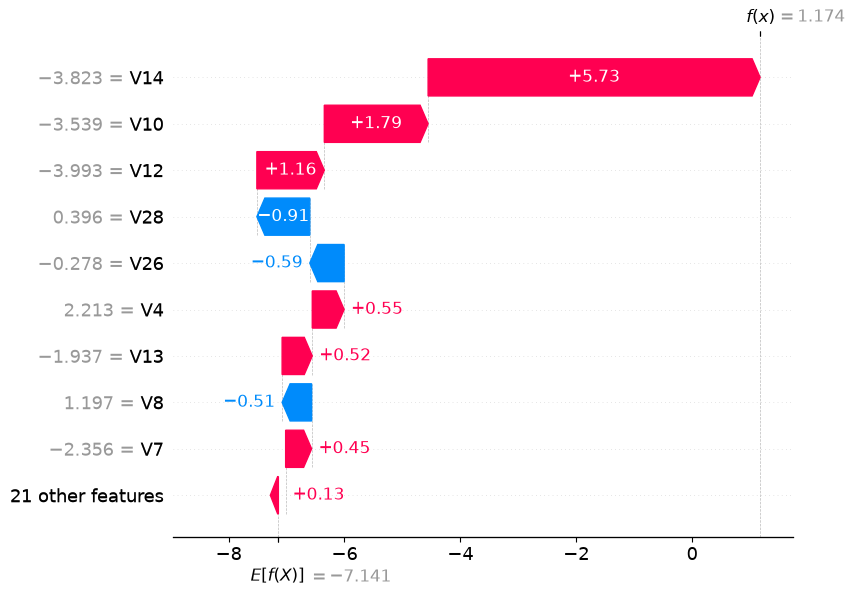

In [86]:
shap.waterfall_plot(
    shap.Explanation(
        values=local_shap,
        base_values=explainer.expected_value,
        data=X_test.loc[idx].values,
        feature_names=X_test.columns
    ),
    max_display=10
)

In [87]:
top10_share = (
    shap_importance.head(10)["Mean_Abs_SHAP"].sum()
    / shap_importance["Mean_Abs_SHAP"].sum()
) * 100

print(f"Top 10 features account for {top10_share:.2f}% of total mean absolute SHAP importance.")

Top 10 features account for 64.02% of total mean absolute SHAP importance.


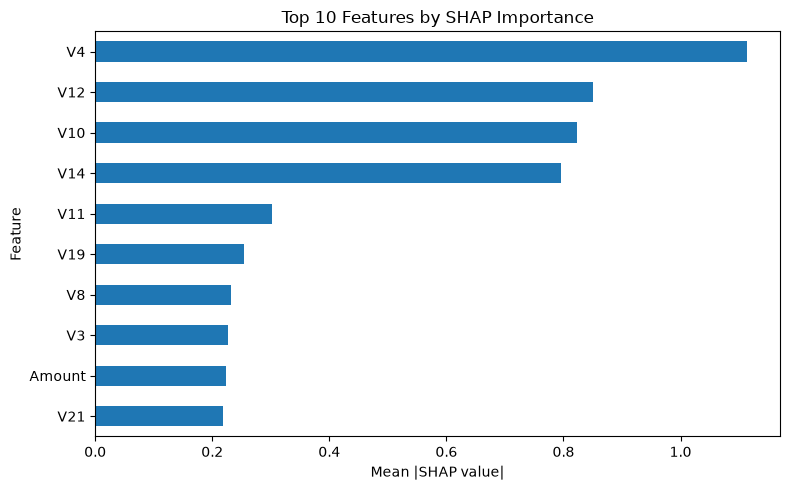

In [88]:
shap_importance.head(10).plot(
    kind="barh",
    x="Feature",
    y="Mean_Abs_SHAP",
    legend=False,
    figsize=(8, 5)
)

plt.xlabel("Mean |SHAP value|")
plt.ylabel("Feature")
plt.title("Top 10 Features by SHAP Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [89]:
print("F1-optimal threshold:", best_threshold)
print("Cost-optimal threshold:", best_cost_threshold)

F1-optimal threshold: 0.38788387
Cost-optimal threshold: 0.10888907


In [90]:
thresholds_to_compare = {
    "F1-optimal": best_threshold,
    "Cost-optimal": best_cost_threshold
}

for name, threshold in thresholds_to_compare.items():
    y_pred = (xgb_val.predict_proba(X_val)[:, 1] >= threshold).astype(int)

    cm = confusion_matrix(y_val, y_pred)
    tn, fp, fn, tp = cm.ravel()

    precision = precision_score(y_val, y_pred)
    recall = recall_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred)

    print(f"\n{name} | Threshold = {threshold:.4f}")
    print(f"TP: {tp} | FP: {fp} | FN: {fn} | TN: {tn}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall:    {recall:.4f}")
    print(f"F1:        {f1:.4f}")
    print(f"Cost:      {fp * C_FP + fn * C_FN:.0f}")


F1-optimal | Threshold = 0.3879
TP: 64 | FP: 1 | FN: 12 | TN: 45319
Precision: 0.9846
Recall:    0.8421
F1:        0.9078
Cost:      121

Cost-optimal | Threshold = 0.1089
TP: 66 | FP: 4 | FN: 10 | TN: 45316
Precision: 0.9429
Recall:    0.8684
F1:        0.9041
Cost:      104


In [91]:
for fn_cost in [1, 5, 10, 20, 50]:
    f1_cost = 1 * C_FP + 12 * fn_cost
    cost_cost = 4 * C_FP + 10 * fn_cost

    print(
        f"FN cost = {fn_cost:>2} | "
        f"F1 threshold cost = {f1_cost:>3} | "
        f"Cost threshold cost = {cost_cost:>3}"
    )

FN cost =  1 | F1 threshold cost =  13 | Cost threshold cost =  14
FN cost =  5 | F1 threshold cost =  61 | Cost threshold cost =  54
FN cost = 10 | F1 threshold cost = 121 | Cost threshold cost = 104
FN cost = 20 | F1 threshold cost = 241 | Cost threshold cost = 204
FN cost = 50 | F1 threshold cost = 601 | Cost threshold cost = 504


In [92]:
import duckdb

con = duckdb.connect()

con.register("transactions", df)

print(con.execute("""
    SELECT COUNT(*) AS total_transactions
    FROM transactions
""").fetchdf())

   total_transactions
0              283726


In [93]:
fraud_summary = con.execute("""
    SELECT
        Class,
        COUNT(*) AS transaction_count,
        ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 4) AS percentage
    FROM transactions
    GROUP BY Class
    ORDER BY Class
""").fetchdf()

fraud_summary

,Class,transaction_count,percentage
0,0,283253,99.8333
1,1,473,0.1667


In [94]:
amount_analysis = con.execute("""
    SELECT
        CASE
            WHEN Amount <= 1 THEN '0-1'
            WHEN Amount <= 10 THEN '1-10'
            WHEN Amount <= 50 THEN '10-50'
            WHEN Amount <= 100 THEN '50-100'
            WHEN Amount <= 500 THEN '100-500'
            ELSE '500+'
        END AS amount_bucket,

        COUNT(*) AS transaction_count,

        SUM(Class) AS fraud_count,

        ROUND(
            100.0 * SUM(Class) / COUNT(*),
            4
        ) AS fraud_rate_pct

    FROM transactions

    GROUP BY amount_bucket

    ORDER BY
        CASE amount_bucket
            WHEN '0-1' THEN 1
            WHEN '1-10' THEN 2
            WHEN '10-50' THEN 3
            WHEN '50-100' THEN 4
            WHEN '100-500' THEN 5
            WHEN '500+' THEN 6
        END
""").fetchdf()

amount_analysis

,amount_bucket,transaction_count,fraud_count,fraud_rate_pct
0,0-1,30331,171.0,0.5638
1,1-10,69490,67.0,0.0964
2,10-50,90327,55.0,0.0609
3,50-100,37179,55.0,0.1479
4,100-500,47290,91.0,0.1924
5,500+,9109,34.0,0.3733


In [95]:
time_analysis = con.execute("""
    SELECT
        CASE
            WHEN Time < 28800 THEN 'Period 1'
            WHEN Time < 57600 THEN 'Period 2'
            WHEN Time < 86400 THEN 'Period 3'
            WHEN Time < 115200 THEN 'Period 4'
            WHEN Time < 144000 THEN 'Period 5'
            ELSE 'Period 6'
        END AS time_period,

        COUNT(*) AS transaction_count,

        SUM(Class) AS fraud_count,

        ROUND(
            100.0 * SUM(Class) / COUNT(*),
            4
        ) AS fraud_rate_pct

    FROM transactions

    GROUP BY time_period

    ORDER BY time_period
""").fetchdf()

time_analysis

,time_period,transaction_count,fraud_count,fraud_rate_pct
0,Period 1,17484,81.0,0.4633
1,Period 2,60796,110.0,0.1809
2,Period 3,65956,81.0,0.1228
3,Period 4,17673,66.0,0.3735
4,Period 5,62127,59.0,0.0950
5,Period 6,59690,76.0,0.1273


In [96]:
class_summary = con.execute("""
    SELECT
        Class,
        COUNT(*) AS transaction_count,
        ROUND(AVG(Amount), 2) AS avg_amount,
        ROUND(MEDIAN(Amount), 2) AS median_amount,
        ROUND(MIN(Amount), 2) AS min_amount,
        ROUND(MAX(Amount), 2) AS max_amount,
        ROUND(SUM(Amount), 2) AS total_amount
    FROM transactions
    GROUP BY Class
    ORDER BY Class
""").fetchdf()

class_summary

,Class,transaction_count,avg_amount,median_amount,min_amount,max_amount,total_amount
0,0,283253,88.41,22.00,0.0,25691.16,25043410.29
1,1,473,123.87,9.82,0.0,2125.87,58591.39


In [97]:
value_share = con.execute("""
    SELECT
        ROUND(
            100.0 * SUM(CASE WHEN Class = 1 THEN Amount ELSE 0 END)
            / SUM(Amount),
            4
        ) AS fraud_value_share_pct,

        ROUND(
            100.0 * SUM(CASE WHEN Class = 1 THEN 1 ELSE 0 END)
            / COUNT(*),
            4
        ) AS fraud_transaction_share_pct
    FROM transactions
""").fetchdf()

value_share

,fraud_value_share_pct,fraud_transaction_share_pct
0,0.2334,0.1667


In [98]:
top_fraud = con.execute("""
    SELECT
        Time,
        Amount,
        Class
    FROM transactions
    WHERE Class = 1
    ORDER BY Amount DESC
    LIMIT 10
""").fetchdf()

top_fraud

,Time,Amount,Class
0,122608.0,2125.87,1
1,9064.0,1809.68,1
2,154278.0,1504.93,1
3,62467.0,1402.16,1
4,59011.0,1389.56,1
5,65385.0,1354.25,1
6,133184.0,1335.00,1
7,18088.0,1218.89,1
8,154309.0,1096.99,1
9,147501.0,996.27,1


In [99]:
fraud_distribution = con.execute("""
    SELECT
        CASE
            WHEN Amount <= 1 THEN '0-1'
            WHEN Amount <= 10 THEN '1-10'
            WHEN Amount <= 50 THEN '10-50'
            WHEN Amount <= 100 THEN '50-100'
            WHEN Amount <= 500 THEN '100-500'
            ELSE '500+'
        END AS amount_bucket,

        COUNT(*) AS fraud_count,

        ROUND(
            100.0 * COUNT(*) /
            SUM(COUNT(*)) OVER (),
            2
        ) AS share_of_fraud_pct

    FROM transactions

    WHERE Class = 1

    GROUP BY amount_bucket

    ORDER BY
        CASE amount_bucket
            WHEN '0-1' THEN 1
            WHEN '1-10' THEN 2
            WHEN '10-50' THEN 3
            WHEN '50-100' THEN 4
            WHEN '100-500' THEN 5
            WHEN '500+' THEN 6
        END
""").fetchdf()

fraud_distribution

,amount_bucket,fraud_count,share_of_fraud_pct
0,0-1,171,36.15
1,1-10,67,14.16
2,10-50,55,11.63
3,50-100,55,11.63
4,100-500,91,19.24
5,500+,34,7.19


In [100]:
dashboard_amount = con.execute("""
    SELECT
        CASE
            WHEN Amount <= 1 THEN '0-1'
            WHEN Amount <= 10 THEN '1-10'
            WHEN Amount <= 50 THEN '10-50'
            WHEN Amount <= 100 THEN '50-100'
            WHEN Amount <= 500 THEN '100-500'
            ELSE '500+'
        END AS amount_bucket,

        COUNT(*) AS transaction_count,

        SUM(Class) AS fraud_count,

        ROUND(
            100.0 * SUM(Class) / COUNT(*),
            4
        ) AS fraud_rate_pct,

        ROUND(SUM(Amount), 2) AS total_transaction_value

    FROM transactions

    GROUP BY amount_bucket

    ORDER BY
        CASE amount_bucket
            WHEN '0-1' THEN 1
            WHEN '1-10' THEN 2
            WHEN '10-50' THEN 3
            WHEN '50-100' THEN 4
            WHEN '100-500' THEN 5
            WHEN '500+' THEN 6
        END
""").fetchdf()

dashboard_amount

,amount_bucket,transaction_count,fraud_count,fraud_rate_pct,total_transaction_value
0,0-1,30331,171.0,0.5638,25146.97
1,1-10,69490,67.0,0.0964,362998.61
2,10-50,90327,55.0,0.0609,2345737.54
3,50-100,37179,55.0,0.1479,2725488.21
4,100-500,47290,91.0,0.1924,10053903.15
5,500+,9109,34.0,0.3733,9588727.20


In [101]:
print("Model:", type(xgb_final).__name__)
print("Features:", X_train_final.shape[1])
print("Threshold:", final_cost_threshold)
print("Scaler:", type(scaler).__name__)
print("SHAP explainer:", type(explainer).__name__)

Model: XGBClassifier
Features: 30
Threshold: 0.10888907
Scaler: StandardScaler
SHAP explainer: TreeExplainer


In [102]:
import joblib

MODEL_PATH = PROJECT_ROOT / "models" / "xgb_final.joblib"

joblib.dump(xgb_final, MODEL_PATH)

print(f"Model saved to: {MODEL_PATH}")

Model saved to: /Users/sneha/credit-card-fraud-xai/models/xgb_final.joblib


In [103]:
import json

MODEL_CONFIG = {
    "threshold": float(final_cost_threshold),
    "features": X_train_final.columns.tolist()
}

CONFIG_PATH = PROJECT_ROOT / "models" / "model_config.json"

with open(CONFIG_PATH, "w") as f:
    json.dump(MODEL_CONFIG, f, indent=4)

print(f"Config saved to: {CONFIG_PATH}")
print(MODEL_CONFIG)

Config saved to: /Users/sneha/credit-card-fraud-xai/models/model_config.json
{'threshold': 0.10888907313346863, 'features': ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']}


In [104]:
import joblib
import json

loaded_model = joblib.load(PROJECT_ROOT / "models" / "xgb_final.joblib")

with open(PROJECT_ROOT / "models" / "model_config.json", "r") as f:
    loaded_config = json.load(f)

print("Model loaded:", type(loaded_model).__name__)
print("Threshold:", loaded_config["threshold"])
print("Number of features:", len(loaded_config["features"]))
print("First 5 features:", loaded_config["features"][:5])

Model loaded: XGBClassifier
Threshold: 0.10888907313346863
Number of features: 30
First 5 features: ['Time', 'V1', 'V2', 'V3', 'V4']
